# 09 2025年予測枠と過去データのカバレッジ

2024年末に利用できる学習履歴と2025年の予定を突き合わせる。販売可能な日×店舗×商品のうち、過去に同じ店舗・商品・曜日の正の売上があったかを確認する。**2025年の正解は使わない。** 行数は日ごとに繰り返された予測枠の数であり、店舗・商品の独立した件数ではない。

ここでの販売可否はカタログ期間とコラボ参加店舗に基づく計画上の判定で、実際に売れることを保証しない。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'input').is_dir(): ROOT=ROOT.parent
assert (ROOT/'input').is_dir()
INPUT=ROOT/'input'; sns.set_theme(style='whitegrid'); pd.options.display.float_format='{:,.3f}'.format
train=pd.read_csv(INPUT/'train.csv',parse_dates=['date'])
test=pd.read_csv(INPUT/'test.csv',parse_dates=['date']).drop(columns='sales_amount')
menus=pd.read_csv(INPUT/'menus.csv'); stores=pd.read_csv(INPUT/'stores.csv').store_id.tolist()
catalog=pd.read_csv(INPUT/'menu_catalog_history.csv',parse_dates=['effective_start_date','effective_end_date'])
catalog['date']=[pd.date_range(a,b) for a,b in zip(catalog.effective_start_date,catalog.effective_end_date)]
catalog=catalog.explode('date',ignore_index=True)[['date','item_id','campaign_id']];catalog['catalog_active']=True
assert not catalog.duplicated(['date','item_id']).any()
campaign=pd.read_csv(INPUT/'campaign_calendar.csv',parse_dates=['date'])
campaign['store_id']=campaign.store_ids.map(lambda x:stores if x=='all' else x.split('|'))
campaign=campaign.explode('store_id',ignore_index=True)
participating=campaign[['date','store_id','campaign_id']].assign(campaign_active=True)
assert not participating.duplicated(['date','store_id','campaign_id']).any()
test=(test.merge(menus[['item_id','category','menu_type']],on='item_id',validate='many_to_one')
      .merge(catalog,on=['date','item_id'],how='left',validate='many_to_one')
      .merge(participating,on=['date','store_id','campaign_id'],how='left',validate='many_to_one'))
test['eligible']=test.catalog_active.fillna(False).astype(bool)&(test.menu_type.ne('collaboration')|test.campaign_active.fillna(False).astype(bool))
test['weekday']=test.date.dt.dayofweek;test['month']=test.date.dt.month
train['weekday']=train.date.dt.dayofweek
assert len(test)==306600
print('2025全予測枠:',len(test),'計画上販売可能:',int(test.eligible.sum()))

2025全予測枠: 306600 計画上販売可能: 230028


## 過去の正の売上履歴の有無
2022〜2024年の train の正の売上が1件以上あれば「あり」。同一の企画内容での売上履歴があることまでは保証しない。

In [2]:
positive=train[train.sales_amount.gt(0)].copy()
by_item=positive.groupby(['store_id','item_id'],observed=True).agg(first_positive=('date','min'),last_positive=('date','max'),positive_days=('date','size')).reset_index()
by_weekday=positive.groupby(['store_id','item_id','weekday'],observed=True).agg(positive_weekdays=('date','size')).reset_index()
test=(test.merge(by_item,on=['store_id','item_id'],how='left',validate='many_to_one')
      .merge(by_weekday,on=['store_id','item_id','weekday'],how='left',validate='many_to_one'))
test['has_positive']=test.positive_days.notna();test['has_weekday_positive']=test.positive_weekdays.notna()
eligible=test[test.eligible]
summary=eligible.groupby('menu_type',observed=True).agg(rows=('item_id','size'),unique_items=('item_id','nunique'),store_item_pairs=('store_id',lambda x: 0),missing_store_item_history=('has_positive',lambda x:(~x).sum()),missing_store_item_weekday_history=('has_weekday_positive',lambda x:(~x).sum()))
pair_counts=eligible.drop_duplicates(['menu_type','store_id','item_id']).groupby('menu_type',observed=True).size()
summary['store_item_pairs']=pair_counts
summary['missing_weekday_fraction']=summary.missing_store_item_weekday_history/summary.rows
display(summary)
missing=eligible[~eligible.has_weekday_positive]
print('過去に同一店舗・商品・曜日の正売上がない販売可能な予測行:',len(missing))
display(missing.groupby(['menu_type','category'],observed=True).agg(rows=('item_id','size'),items=('item_id','nunique'),stores=('store_id','nunique')))
display(missing[['store_id','item_id','category','menu_type']].drop_duplicates().sort_values(['menu_type','store_id','item_id']).head(30))

過去に同一店舗・商品・曜日の正売上がない販売可能な予測行: 324


,rows,unique_items,store_item_pairs,missing_store_item_history,missing_store_item_weekday_history,missing_weekday_fraction
menu_type,,,,,,
collaboration,2808,9,78,324,324,0.115
core,215350,59,590,0,0,0.000
seasonal,11870,13,130,0,0,0.000


rows  items  stores
menu_type     category                     
collaboration dessert    108      2       3
              kids        36      1       1
              main       108      2       3
              side        72      1       2

,store_id,item_id,category,menu_type
31071,S002,M076,main,collaboration
31072,S002,M077,side,collaboration
31073,S002,M078,dessert,collaboration
133134,S005,M079,dessert,collaboration
133135,S005,M080,main,collaboration
133136,S005,M081,kids,collaboration
245691,S009,M076,main,collaboration
245692,S009,M077,side,collaboration
245693,S009,M078,dessert,collaboration


## 月別・店舗別の販売可能枠と履歴
`weekdays_without_positive_history` は正売上がなかった枠数であり、訓練データの品質不良とは限らない。販売機会がなかった商品・企画や売上ゼロの組み合わせも含む。

month,1,2,3,4,5,6,7,8,9,10,11,12
store_id,,,,,,,,,,,,
S001,0,0,0,0,0,0,0,0,0,0,0,0
S002,81,27,0,0,0,0,0,0,0,0,0,0
S003,0,0,0,0,0,0,0,0,0,0,0,0
S004,0,0,0,0,0,0,0,0,0,0,0,0
S005,0,0,0,0,81,27,0,0,0,0,0,0
S006,0,0,0,0,0,0,0,0,0,0,0,0
S007,0,0,0,0,0,0,0,0,0,0,0,0
S008,0,0,0,0,0,0,0,0,0,0,0,0
S009,81,27,0,0,0,0,0,0,0,0,0,0


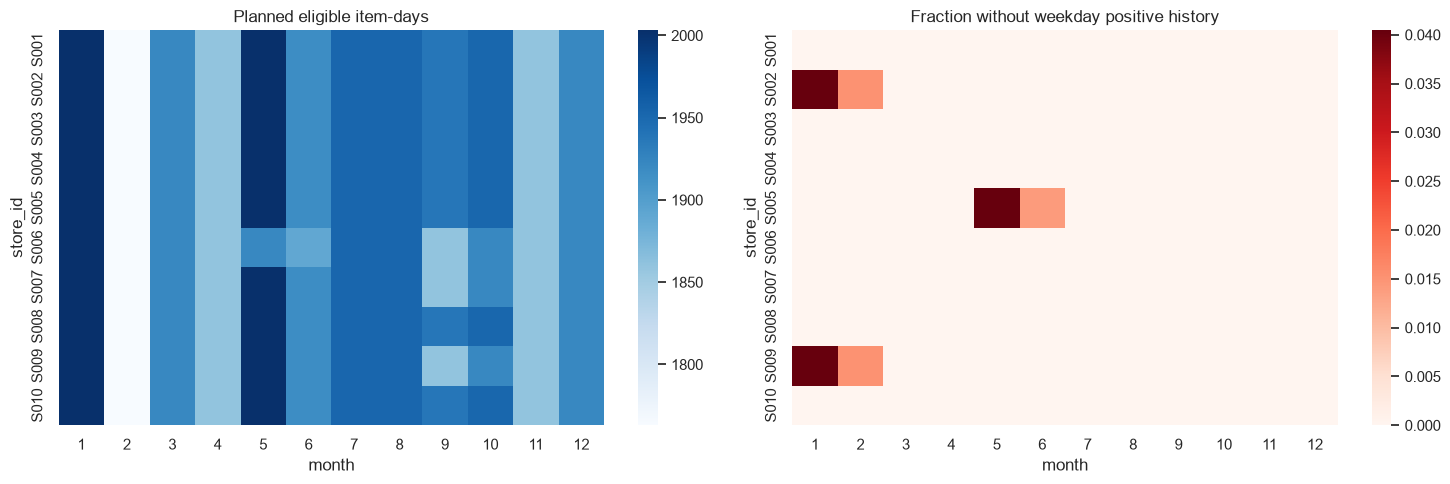

In [3]:
coverage=eligible.groupby(['month','store_id'],observed=True).agg(eligible_rows=('item_id','size'),weekdays_without_positive_history=('has_weekday_positive',lambda x:(~x).sum())).reset_index()
coverage['missing_fraction']=coverage.weekdays_without_positive_history/coverage.eligible_rows
display(coverage.pivot(index='store_id',columns='month',values='weekdays_without_positive_history'))
fig,ax=plt.subplots(1,2,figsize=(15,5));sns.heatmap(coverage.pivot(index='store_id',columns='month',values='eligible_rows').astype(float),cmap='Blues',ax=ax[0]);ax[0].set(title='Planned eligible item-days',xlabel='month');sns.heatmap(coverage.pivot(index='store_id',columns='month',values='missing_fraction').astype(float),vmin=0,cmap='Reds',ax=ax[1]);ax[1].set(title='Fraction without weekday positive history',xlabel='month');plt.tight_layout();plt.show()

## 日付・祝日・天候平年値の年次差
日数、曜日配置、祝日の関係は年で異なる。天候の実績ではなく、予測期間にも配布されている平年値を比較する。

year,2022,2023,2024,2025
weekday,,,,
0,52,52,53,52
1,52,52,53,52
2,52,52,52,53
3,52,52,52,52
4,52,52,52,52
5,53,52,52,52
6,52,53,52,52


year,2022,2023,2024,2025
weekday,,,,
0,5,5,11,9
1,1,1,0,4
2,3,1,1,1
3,3,3,0,1
4,3,3,2,0
5,1,3,2,1
6,0,1,5,3


year,2024,2025
month,,
1,2,2
2,3,3
3,1,1
4,1,1
5,4,4
6,0,0
7,1,1
8,2,1
9,3,2


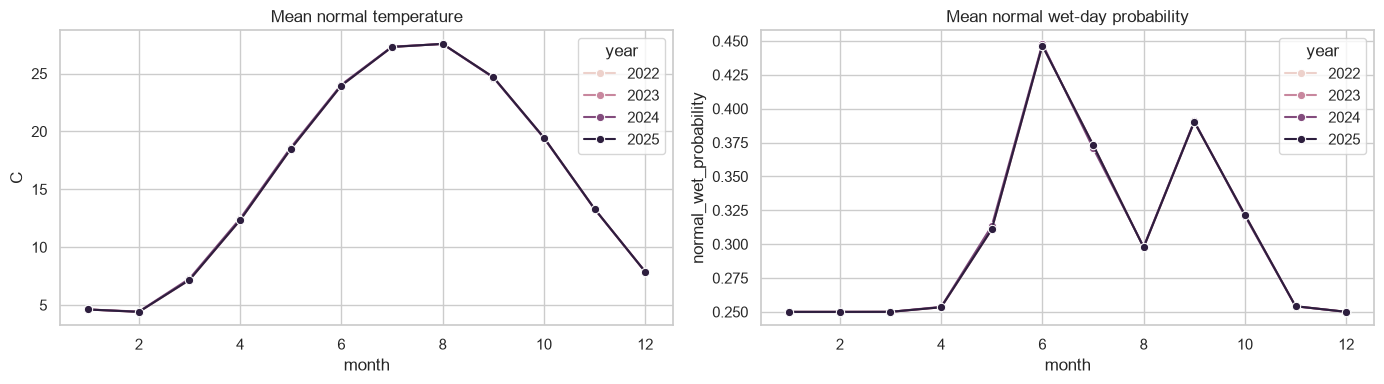

In [4]:
cal=pd.read_csv(INPUT/'calendar.csv',parse_dates=['date']);cal['year']=cal.date.dt.year;cal['month']=cal.date.dt.month;cal['weekday']=cal.date.dt.dayofweek
calendar_counts=cal.groupby(['year','weekday']).agg(days=('date','size'),holidays=('is_holiday','sum')).reset_index();display(calendar_counts.pivot(index='weekday',columns='year',values='days'));display(calendar_counts.pivot(index='weekday',columns='year',values='holidays'))
monthly=cal.groupby(['year','month'],as_index=False).agg(holiday_days=('is_holiday','sum'),normal_temperature=('temperature_normal','mean'),normal_wet_probability=('wet_probability_normal','mean'),normal_precipitation=('precipitation_normal','mean'))
display(monthly[monthly.year.isin([2024,2025])].pivot(index='month',columns='year',values='holiday_days'))
fig,ax=plt.subplots(1,2,figsize=(14,4));sns.lineplot(data=monthly,x='month',y='normal_temperature',hue='year',marker='o',ax=ax[0]);ax[0].set(title='Mean normal temperature',ylabel='C');sns.lineplot(data=monthly,x='month',y='normal_wet_probability',hue='year',marker='o',ax=ax[1]);ax[1].set(title='Mean normal wet-day probability');plt.tight_layout();plt.show()

## 使用上の注意
- 正売上の履歴がない場合、カテゴリや他店舗などの過去情報を使う代替方法を検討し、その選択は時間順の検証で評価する。
- 2025年のコラボ開催店舗・時期は過去と異なる。日付と企画ID・店舗を照合し、単純に前年の日付をコピーしない。
- 将来日の祝日、天候平年値、施策・価格・販売期間の予定と、予測時点で未観測の実績を区別する。